In [81]:
import pandas as pd

pd.set_option('display.float_format', '{:.2f}'.format)

import numpy as np

np.set_printoptions(suppress=True, precision=4)

In [82]:
df = pd.read_csv("spam.csv", encoding='latin-1')

df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1527,ham,No screaming means shouting..,NaN,NaN,NaN
1531,ham,Oh dang! I didn't mean o send that to you! Lol!,NaN,NaN,NaN
1593,spam,PRIVATE! Your 2003 Account Statement for shows...,NaN,NaN,NaN
897,ham,I'm used to it. I just hope my agents don't dr...,NaN,NaN,NaN
3134,ham,Wat makes some people dearer is not just de ha...,NaN,NaN,NaN


In [83]:
df.shape

(5572, 5)

# We will complete this project in 5 steps.
1. Data Cleaning
2. EDA
3. Text Preprocessing
4. Model Building
5. Model Evaluation
6. Improvements depending on evaluation

# 1. Data Cleaning

In [84]:
# Check if Unnamed: 2, 3 and 4 are required or can we drop these columns

df.info()

# We can see that in these three columns, almost 99% values are missing. So we can drop these columns.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [85]:
df.iloc[:, 2:5].columns

Index(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

In [86]:
# Droping Unnamed 2, 3 and 4

df.drop(columns = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'] , inplace = True)

df.sample(5)

,v1,v2
1595,ham,Pls confirm the time to collect the cheque.
1578,ham,How to Make a girl Happy? It's not at all diff...
4745,ham,Orh i tot u say she now still dun believe.
1809,ham,"Aight, I'll ask a few of my roommates"
5104,ham,A Boy loved a gal. He propsd bt she didnt mind...


In [87]:
# Column names v1 and v2 are confusing so renaming column names

rename_columns  = {'v1': 'target', 'v2': 'text'}
df.rename(columns=rename_columns, inplace = True)

# Taking target to last position

df = df[['text', 'target']]

df.sample(5)

,text,target
4243,"Aight, I'm chillin in a friend's room so text ...",ham
5056,Hey next sun 1030 there's a basic yoga course....,ham
2614,"Sir, hope your day is going smoothly. i really...",ham
1281,Am I the only one who doesn't stalk profiles?,ham
2417,Oh... Lk tt den we take e one tt ends at cine ...,ham


In [88]:
df.target.value_counts()

# This is an imbalanced dataset. So as for now, just keep this in mind
# Also, values in target column are 'ham' and 'spam'. So, let's apply label encoding

target
ham     4825
spam     747
Name: count, dtype: int64

In [89]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['target'] = le.fit_transform(df['target'])

df.sample(5)

,text,target
439,But i have to. I like to have love and arrange.,0
5128,Wot about on wed nite I am 3 then but only til 9!,0
3194,Great. P diddy is my neighbor and comes for to...,0
3236,Ron say fri leh. N he said ding tai feng cant ...,0
2843,Today iZ Yellow rose day. If u love my frndshi...,0


In [90]:
le.classes_
# ham=0 and spam = 1

array(['ham', 'spam'], dtype=object)

In [91]:
# Checking missing values
df.isnull().sum()

text      0
target    0
dtype: int64

In [92]:
# Check if duplicare rows are present
df.duplicated().sum()

# There are 403 duplicate values. We will have to drop these rows

np.int64(403)

In [93]:
df.drop_duplicates(keep = 'first', inplace = True)
df.duplicated().sum()


np.int64(0)

In [94]:
df.shape

# Basic cleaning is complete. Now we will move to EDA part

(5169, 2)

# 2. Exploratory Data Analysis (EDA)

In [95]:
# Check how many rows are there in each target
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

In [96]:
import matplotlib.pyplot as plt

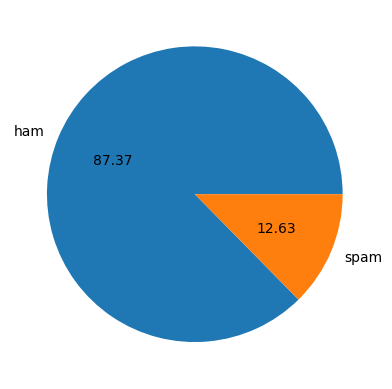

In [97]:
plt.pie(df['target'].value_counts(), labels = le.classes_, autopct="%0.2f")
plt.show()    # To avoide extra texts

In [98]:
# Now, we will do some deeper analysis.
# We will create 3 new columns.
# 1) No_of_characters in an SMS
# 2) No_of words in the SMS and
# 3) No_of sentences in the SMS

# To perform this we will need a library 'nltk' which deals with text preprocessing

In [99]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

# nltk need some dependencies to work, so these line downloads the dependencies

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jugal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jugal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [100]:
# Counting no of characters in each SMS

df['total_char'] = df['text'].apply(len)

df.head(5)

,text,target,total_char
0,"Go until jurong point, crazy.. Available only ...",0,111
1,Ok lar... Joking wif u oni...,0,29
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,155
3,U dun say so early hor... U c already then say...,0,49
4,"Nah I don't think he goes to usf, he lives aro...",0,61


In [101]:
# Now we will create a column for no_of words

df['text'][0]

'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

In [102]:
word_tokenizer = lambda x: nltk.word_tokenize(x)
word_count = lambda x: len(nltk.word_tokenize(x))

In [103]:
word_tokenizer(df['text'][0])

['Go',
 'until',
 'jurong',
 'point',
 ',',
 'crazy',
 '..',
 'Available',
 'only',
 'in',
 'bugis',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 '...',
 'Cine',
 'there',
 'got',
 'amore',
 'wat',
 '...']

In [104]:
word_count(df['text'][0])

24

In [105]:
df['total_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))

df.head()

,text,target,total_char,total_words
0,"Go until jurong point, crazy.. Available only ...",0,111,24
1,Ok lar... Joking wif u oni...,0,29,8
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,37
3,U dun say so early hor... U c already then say...,0,49,13
4,"Nah I don't think he goes to usf, he lives aro...",0,61,15


In [106]:
# Now creating a column for no_of sentences

sen_tokenize = lambda x: nltk.sent_tokenize(x)
sen_count = lambda x: len(nltk.sent_tokenize(x))

print(sen_tokenize(df.text[0]))
print(sen_count(df.text[0]))

['Go until jurong point, crazy..', 'Available only in bugis n great world la e buffet... Cine there got amore wat...']
2


In [107]:
df['total_sen'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))
df.head()

,text,target,total_char,total_words,total_sen
0,"Go until jurong point, crazy.. Available only ...",0,111,24,2
1,Ok lar... Joking wif u oni...,0,29,8,2
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,37,2
3,U dun say so early hor... U c already then say...,0,49,13,1
4,"Nah I don't think he goes to usf, he lives aro...",0,61,15,1


In [108]:
# Checking statistics on newly created columns

df.iloc[:, 2:].describe()

,total_char,total_words,total_sen
count,5169.00,5169.00,5169.00
mean,78.98,18.46,1.97
std,58.24,13.32,1.45
min,2.00,1.00,1.00
25%,36.00,9.00,1.00
50%,60.00,15.00,1.00
75%,117.00,26.00,2.00
max,910.00,220.00,38.00


In [109]:
# Seperating ham and span and getting statistics on each

df[df['target'] == 0].iloc[:, 2:].describe()    # For ham

,total_char,total_words,total_sen
count,4516.00,4516.00,4516.00
mean,70.46,17.12,1.82
std,56.36,13.49,1.38
min,2.00,1.00,1.00
25%,34.00,8.00,1.00
50%,52.00,13.00,1.00
75%,90.00,22.00,2.00
max,910.00,220.00,38.00


In [110]:
df[df['target'] == 1].iloc[:, 2:].describe()    # For spam

,total_char,total_words,total_sen
count,653.00,653.00,653.00
mean,137.89,27.67,2.97
std,30.14,7.01,1.49
min,13.00,2.00,1.00
25%,132.00,25.00,2.00
50%,149.00,29.00,3.00
75%,157.00,32.00,4.00
max,224.00,46.00,9.00


In [111]:
# See the mean of both ham and spam
# You will notice that average no_of words, characters and sentences in spam is more than in ham

# Let's plot histogram and visualize this. We will visualize no_of words here but can use other two columns as well
import seaborn as sns

Text(0.5, 1.0, 'Histogram showing total words in Ham and Span')

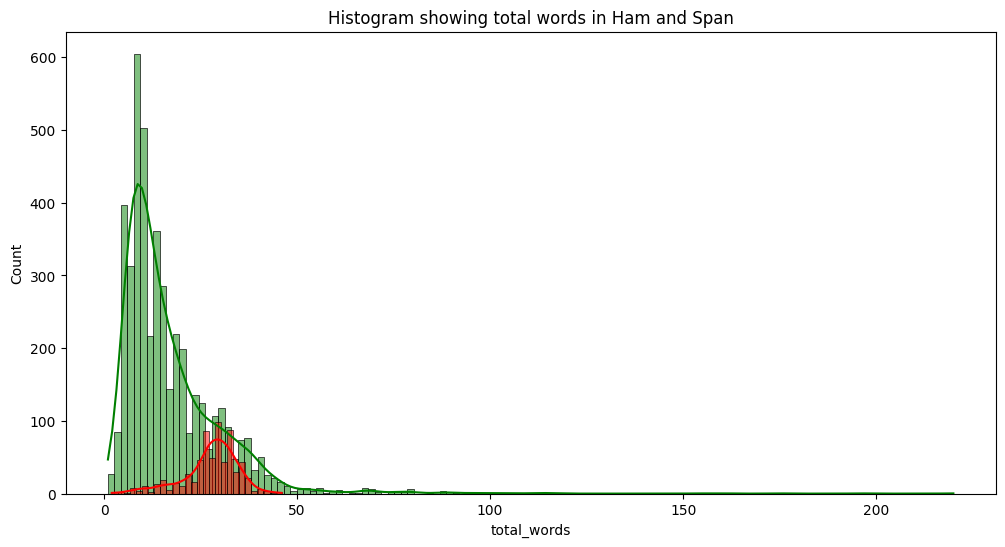

In [112]:
# ham

plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['total_words'], kde = True, color='green')
sns.histplot(df[df['target'] == 1]['total_words'], kde = True, color='red')

plt.title('Histogram showing total words in Ham and Span')

# We can clearly see that the average no of words in Spam is higher than in Span

Text(0.5, 1.0, 'Histogram showing total words in Spam')

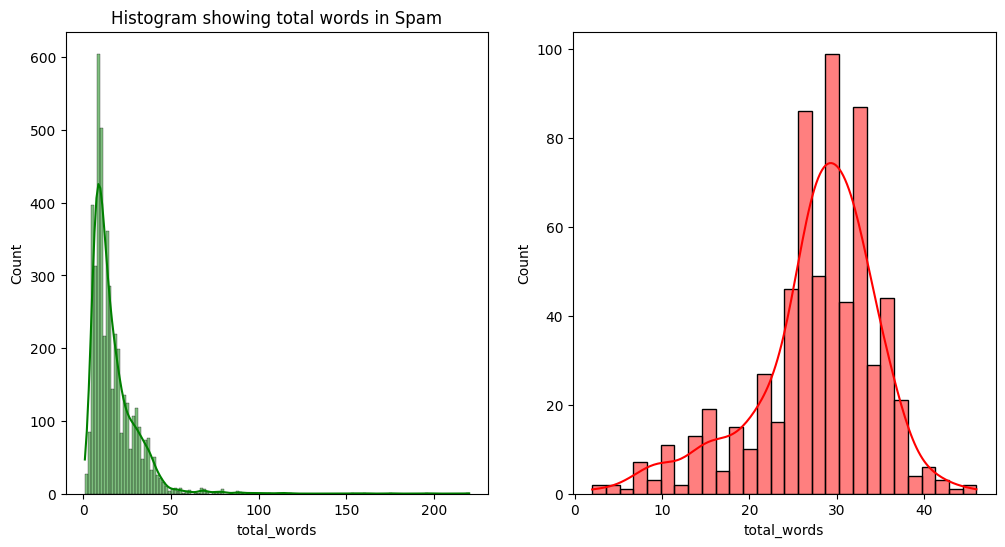

In [113]:
# Spam

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,6))

sns.histplot(df[df['target'] == 0]['total_words'], kde = True, color = 'green', ax = axes[0])
axes[0].set_title('Histogram showing total words in Ham')

sns.histplot(df[df['target'] == 1]['total_words'], kde = True, color = 'red', ax = axes[1])
axes[0].set_title('Histogram showing total words in Spam')

Text(0.5, 1.0, 'Histogram showing total words in Ham and Span')

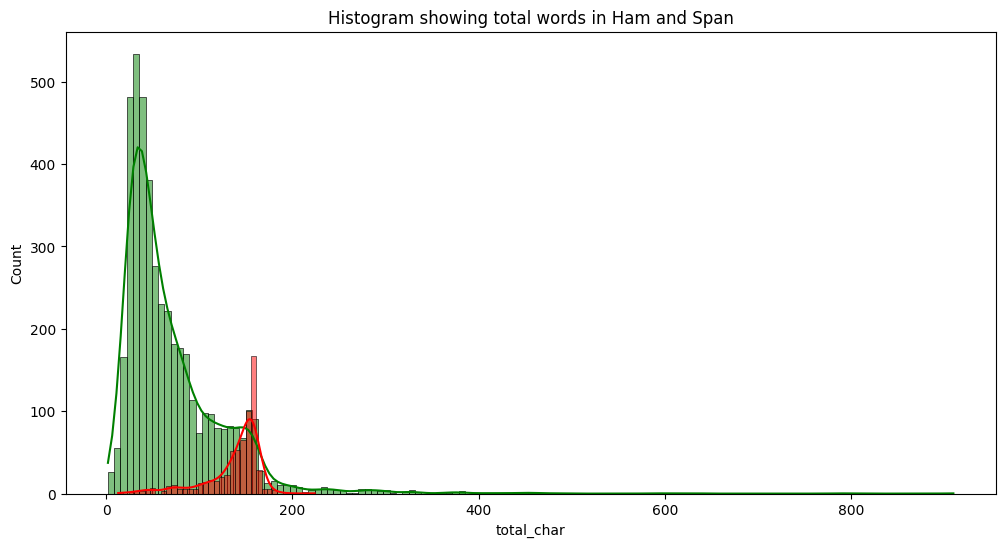

In [114]:
# On number of characters

# ham

plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['total_char'], kde = True, color='green')
sns.histplot(df[df['target'] == 1]['total_char'], kde = True, color='red')

plt.title('Histogram showing total words in Ham and Span')

# We can clearly see that the average no of words in Spam is higher than in Span



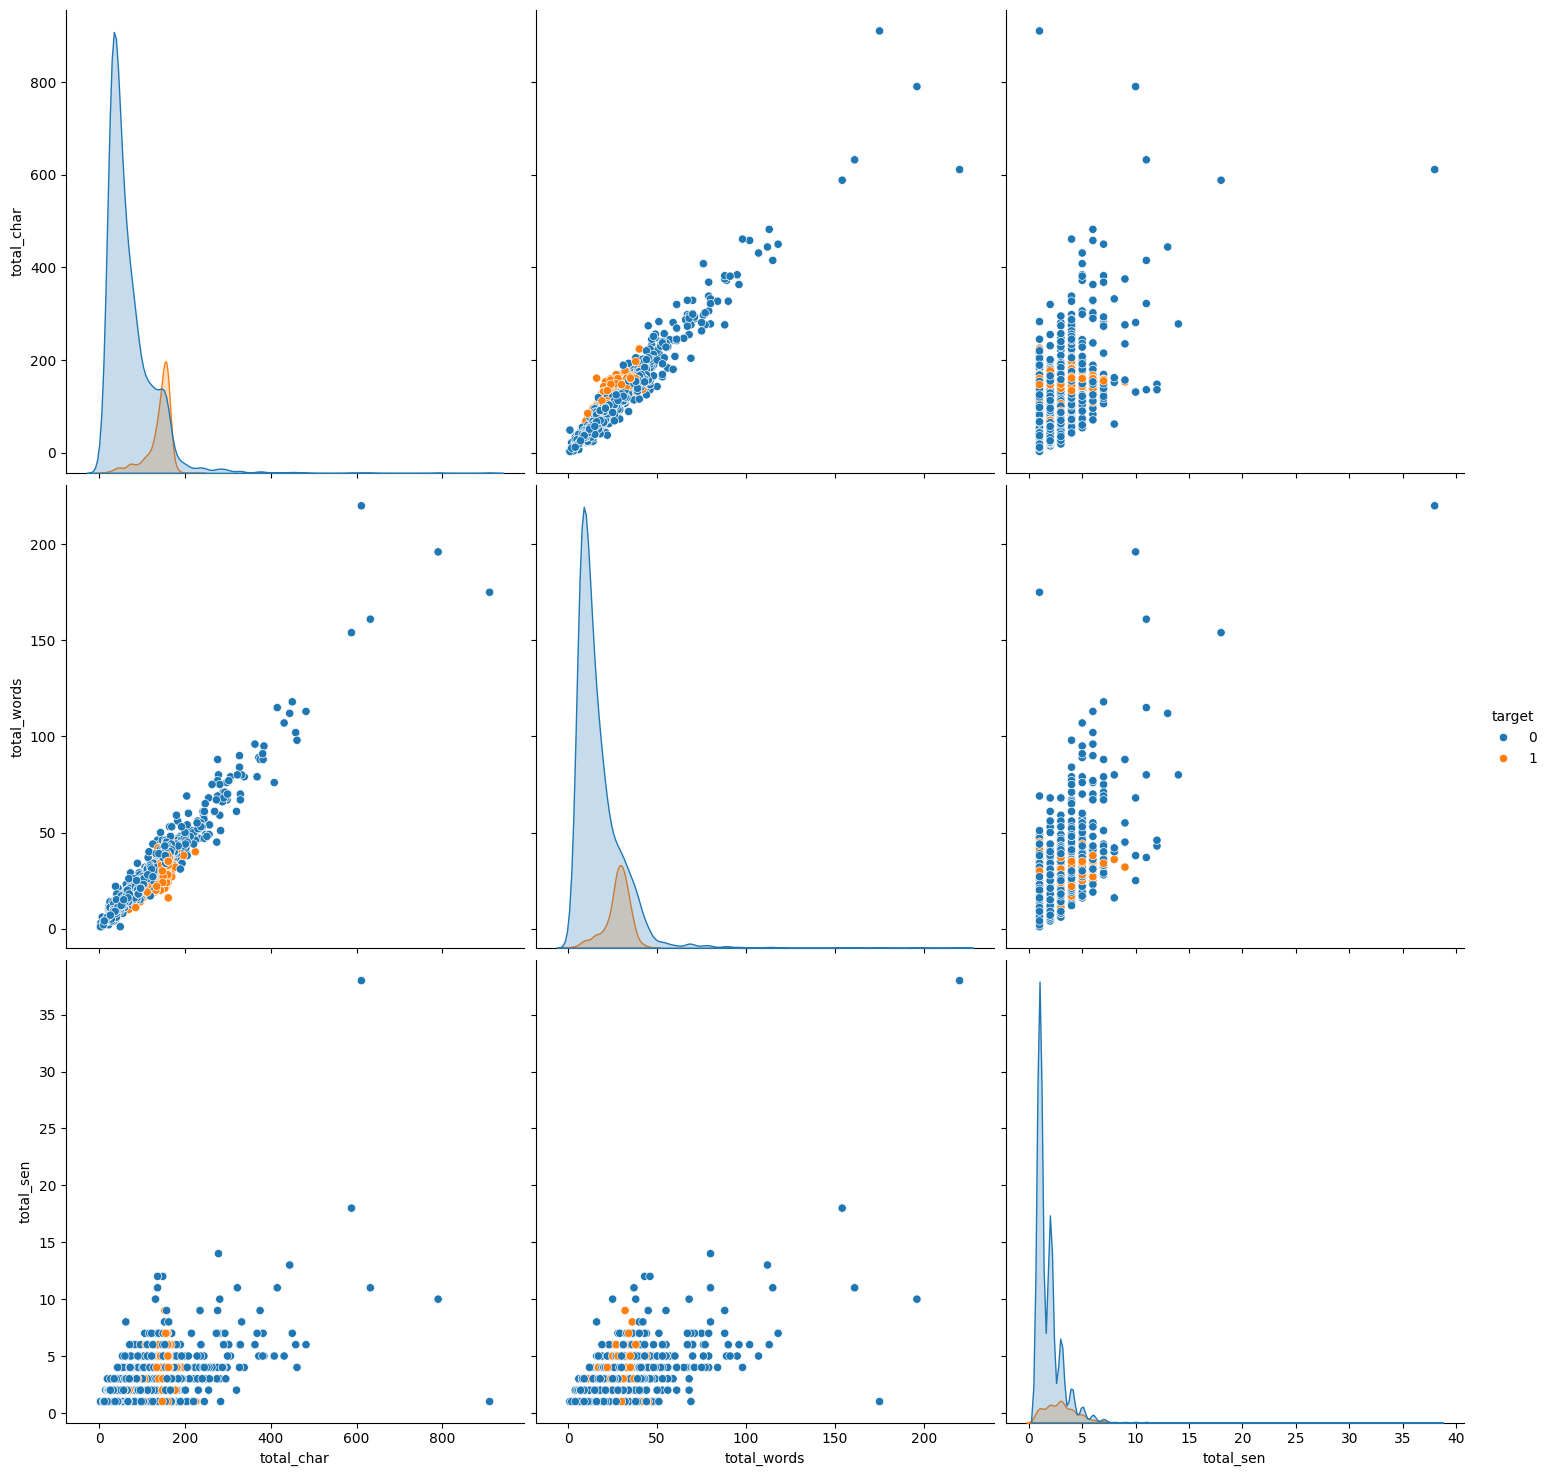

In [115]:
# Let's now see the relation of these columns with other columns.
# We will use sns.pairplot which plots scatterplot of a column with all the other columns

sns.pairplot(df, hue = 'target', height=5)

# We can see that there is somewhat linear relation between total_words, total_char and total_sen
# Also, we can notice the outliers present in these columns

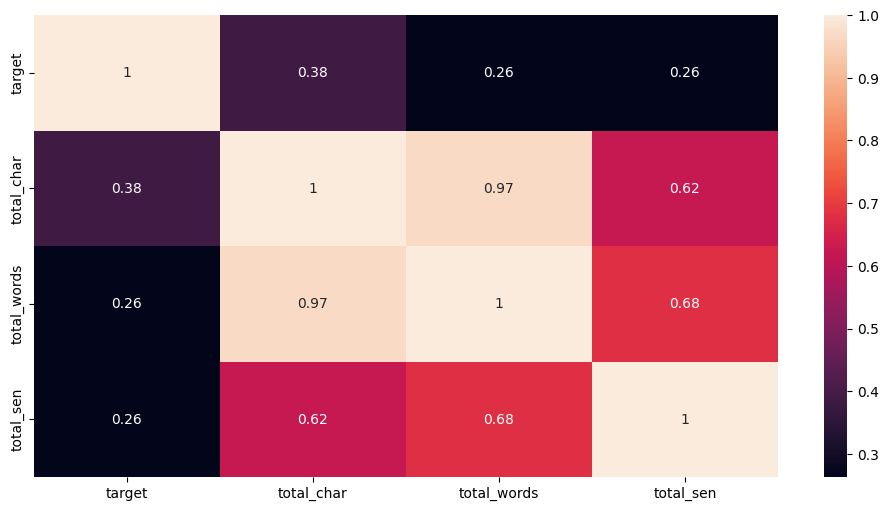

In [116]:
# Plotting correlation

plt.figure(figsize=(12, 6))

sns.heatmap(df.corr(numeric_only=True), annot=True)

plt.show()

# Findings
# 1) total_char and total_words is highly correlated(0.97)
# 2) total_char and total_sen = 0.62
# 3) total_sen and total_words = 0.68

# Conclusing: 
# All these three columns are highly correlated with each other
# This means there is multicolinearity between these 3 columns
# We will have to keep any one from these 3 columns.
# We will keep total_char because it has the highst relation witn target column.

# We will perform this later

# 3) Text Preprocessing
* `Lower Case`
* `Tokenization`: To break the sentence into words
* `Removing special characters` like @, #, $, %, & etc
* `Removing stop words and punctuation`
    * Stop words means those words which doesnt have any importance in the model training like the, is, of etc.
    * We will remove puntuations like . , ; " ! : - . as well bcz they dont have any meaning for training the model
* `Stemming:` Converting words to its root form. 
    * For example: 
        1. Dancing, danced to dance
        2. Running to run

`We will create a function which will perform these step at once`


In [117]:
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer


In [118]:
def transform_text(text):


    # Lower case
    text = text.lower()
    # Word tokenization
    text = nltk.word_tokenize(text)    # This returns a list of words as seperate elements  ['Hii', 'how', 'are', 'you', 20, '%']

    # Removing special characters
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)

    # text = y-> Should not do this. Remember the concept of reference. If we clear y later, it will clear text as well    
    text = y[:]
    y.clear()

    # Removing stop words and punctuation. See what are stop words and puntuations in below cell
    for i in text:
            if i not in stopwords.words('english') and i not in string.punctuation:
                 y.append(i)

    text = y[:]
    y.clear()

    # Stemming: See the code cell below
    for i in text:
         y.append(PorterStemmer().stem(i))

    return ' '.join(y)

In [119]:
transform_text("I loved the YT lectures on Machine Learning. How about you?")

# How are you are stopwords, % and ? are puntuations
# Laughing converted to root rowd laugh
# e is missing in machin and lectur bcz this is some NLP concept. I will see this later. 

'love yt lectur machin learn'

## Why does Stemming remove 'e' from Dance?

Stemming algorithms use predefined rules to remove prefixes and suffixes from words.

For example, using NLTK's Porter Stemmer:

```python
from nltk.stem import PorterStemmer

ps = PorterStemmer()

print(ps.stem('dancing'))
```

**Output:**
```text
danc
```

You might expect `dance`, but why does it return `danc`?

### Why does it remove 'e'?

The Porter Stemmer applies predefined rules to remove suffixes.

For example:

1. `dancing` → Removes `ing`.
2. Result: `danc`.

The algorithm doesn't understand that `dance` is the correct English word. It simply applies its stemming rules to reduce words to their root-like forms.

### Stemming vs Lemmatization

| Stemming | Lemmatization |
|---|---|
| Uses predefined rules to remove prefixes or suffixes. | Uses vocabulary and linguistic information. |
| May produce incomplete words. | Usually produces meaningful dictionary words. |
| dancing → danc | dancing → dance |

### Remember

- **Stemming:** Focuses on reducing words to a common stem.
- **Lemmatization:** Focuses on finding the meaningful base form of a word.

That's why stemming can produce `danc` instead of `dance`.

In [120]:
# Stopwords
from nltk.corpus import stopwords

stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [121]:
# Puntuation
import string

string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [122]:
# Stemming
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

ps.stem('Laughing')

'laugh'

In [125]:
# Transforming original text. Will take some time

df['trans_text'] = df['text'].apply(transform_text)

In [140]:
# Now lets create a wordcloud
# Word cloud displays the word and its size is as per the frequency of that word

# Lets first do it for Spam. So target = 1
from wordcloud import WordCloud

wc = WordCloud(
    height = 1000,
    width = 1000,
    min_font_size = 20,
    background_color = 'white'
)

spam_msg = df[df['target'] == 1] ["trans_text"]
spam_wc = wc.generate(spam_msg.str.cat(sep = ' '))    # Returns wc object

spam_wc

In [141]:
spam_msg

2       free entri 2 wkli comp win fa cup final tkt 21...
5       freemsg hey darl 3 week word back like fun sti...
8       winner valu network custom select receivea pri...
9       mobil 11 month u r entitl updat latest colour ...
11      six chanc win cash 100 pound txt csh11 send co...
                              ...                        
5537    want explicit sex 30 sec ring 02073162414 cost...
5540    ask 3mobil 0870 chatlin inclu free min india c...
5547    contract mobil 11 mnth latest motorola nokia e...
5566    remind o2 get pound free call credit detail gr...
5567    2nd time tri 2 contact u pound prize 2 claim e...
Name: trans_text, Length: 653, dtype: object

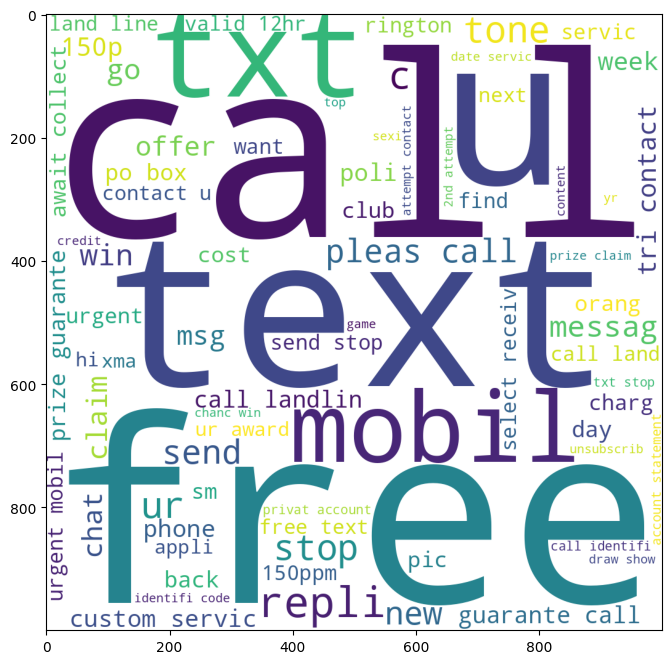

In [ ]:
plt.figure(figsize=(16,8))
plt.imshow(spam_wc)

# See, in spam, the words txt, call, U, mobile, free are having very high frequency.
# We know in real world also, in spam messages, these words appear frequently

In [154]:
wc = WordCloud(
    height = 1000,
    width = 1000,
    min_font_size = 20,
    background_color = 'white'
)

true_msg = df[df['target'] == 0] ["trans_text"]
true_wc = wc.generate(true_msg.str.cat(sep = ' '))    # Returns wc object

true_wc

In [155]:
true_msg

0       go jurong point crazi avail bugi n great world...
1                                   ok lar joke wif u oni
3                     u dun say earli hor u c alreadi say
4                    nah think goe usf live around though
6           even brother like speak treat like aid patent
                              ...                        
5565                                              huh lei
5568                                b go esplanad fr home
5569                                    piti mood suggest
5570    guy bitch act like interest buy someth els nex...
5571                                       rofl true name
Name: trans_text, Length: 4516, dtype: object

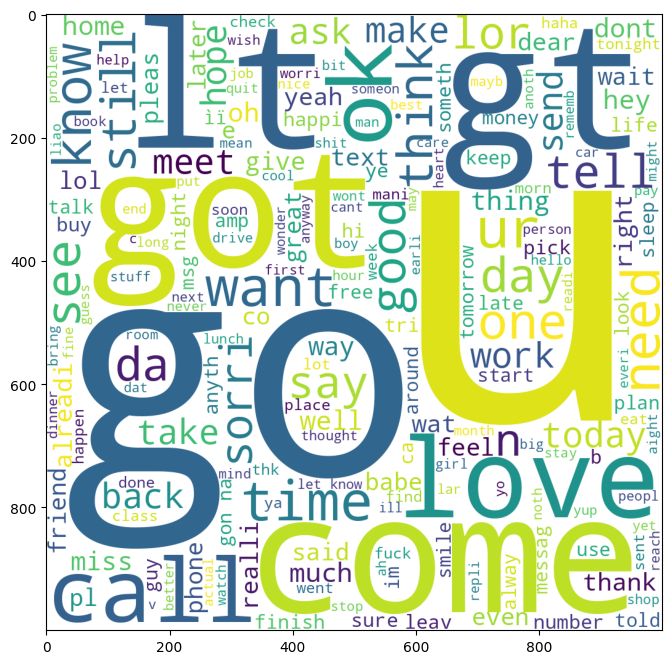

In [ ]:
plt.figure(figsize=(16,8))
plt.imshow(true_wc)

# See, in non_spam, the words like love, go, got, come, call, know are having very high frequency.
# These are the same word we use in our conversations.

In [170]:
spam_corpus = []
for msg in df[df['target'] == 1]  ['trans_text']:
    for word in msg.split():
        spam_corpus.append(word)

In [171]:
from collections import Counter

Counter(spam_corpus).most_common(30)

[('call', 320),
 ('free', 191),
 ('2', 155),
 ('txt', 141),
 ('text', 122),
 ('u', 119),
 ('ur', 119),
 ('mobil', 114),
 ('stop', 104),
 ('repli', 103),
 ('claim', 98),
 ('4', 97),
 ('prize', 82),
 ('get', 74),
 ('new', 64),
 ('servic', 64),
 ('tone', 63),
 ('send', 60),
 ('urgent', 57),
 ('nokia', 57),
 ('contact', 56),
 ('award', 55),
 ('phone', 52),
 ('cash', 51),
 ('pleas', 51),
 ('week', 49),
 ('win', 48),
 ('c', 45),
 ('collect', 45),
 ('min', 45)]

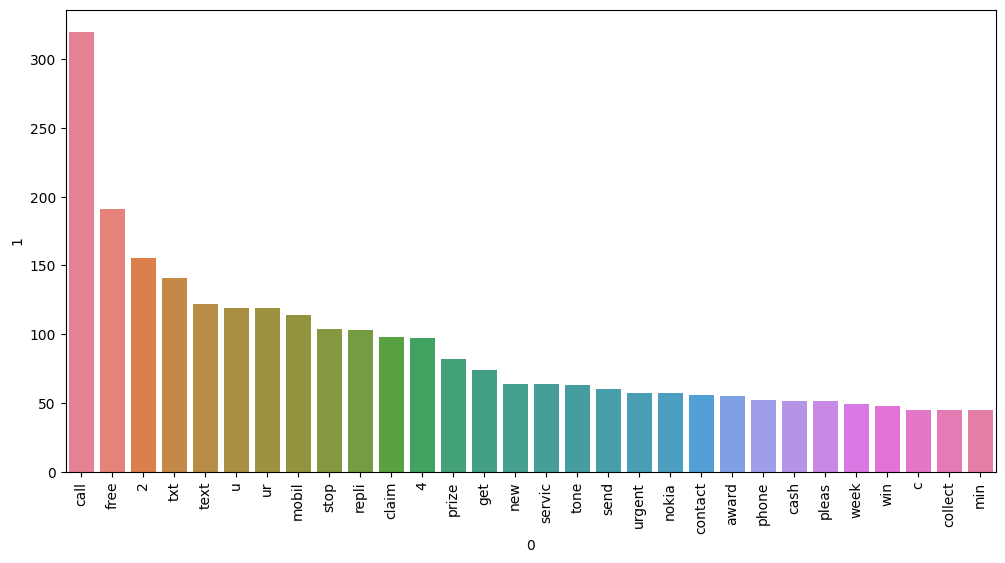

In [ ]:
# Creating DataFrame for this common words

spam_corpus_df = pd.DataFrame(Counter(spam_corpus).most_common(30))

plt.figure(figsize=(12,6))

sns.barplot(
            x = spam_corpus_df[0],
            y = spam_corpus_df[1],
            # hue = spam_corpus_df[0],
            palette = 'husl'    # different color for each bar can give other value other then 'husl'
            )

# plt.xticks(rotation = 90)
plt.xticks(rotation = 'vertical')
plt.show()

In [183]:
spam_corpus_df

,0,1
0,call,320
1,free,191
2,2,155
3,txt,141
4,text,122
5,u,119
6,ur,119
7,mobil,114
8,stop,104
9,repli,103


In [204]:
ham_corpus = []
for msg in df[df['target'] == 0]  ['trans_text']:
    for word in msg.split():
        ham_corpus.append(word)

In [208]:
# Creating DataFrame for this common words

ham_corpus_df = pd.DataFrame(Counter(ham_corpus).most_common(30))

ham_corpus_df

,0,1
0,u,883
1,go,404
2,get,349
3,gt,288
4,lt,287
5,2,284
6,come,275
7,got,236
8,know,236
9,like,234


C:\Users\jugal\AppData\Local\Temp\ipykernel_32100\1811273242.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


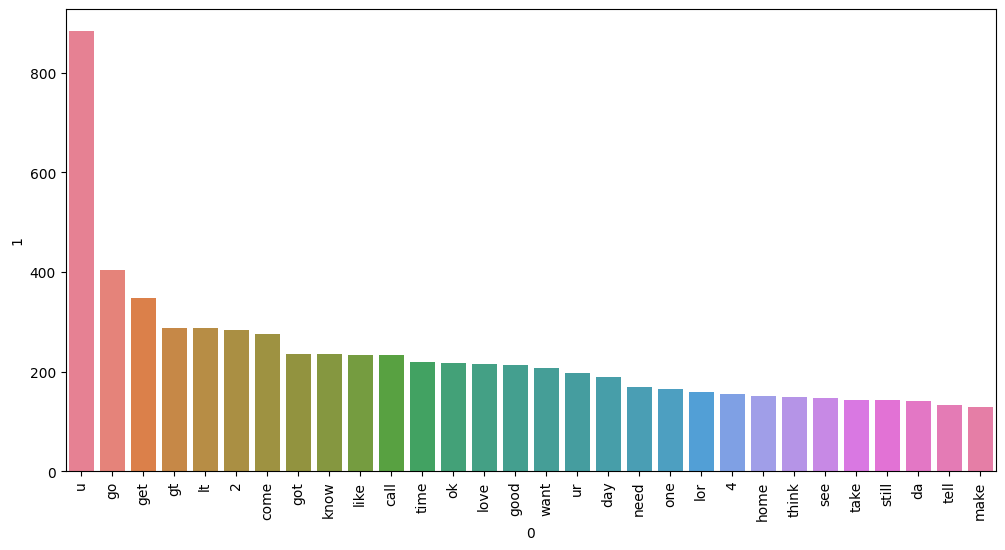

In [209]:
plt.figure(figsize=(12,6))

sns.barplot(
            x = ham_corpus_df[0],
            y = ham_corpus_df[1],
            # hue = spam_corpus_df[0],
            palette = 'husl'    # different color for each bar can give other value other then 'husl'
            )

# plt.xticks(rotation = 90)
plt.xticks(rotation = 'vertical')
plt.show()

# 4) Model Building